In [1]:
#!/usr/bin/env python
# coding: utf-8

# # plot heterogeneous permeability for alluvium (top) layer
#
# Visualizes the interpolated permeability field (from update_permeability.py)
# mapped onto the riverbed mesh triangles, following the same 2D spatial map
# style as plot_temp_from_river_cell.py.
#
# Contact: Chao Zeng, chao.zeng@pnnl.gov

# In[1]:


import numpy as np
import h5py as h5
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.collections import PatchCollection
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from shapely.geometry.polygon import Polygon

from scipy.interpolate import RBFInterpolator
from scipy.ndimage import gaussian_filter1d

In [2]:
# In[2]:

result_dir = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/results/'
# --- file paths ---
fname_material_h5 = '/global/cfs/cdirs/m1800/pin/github/HFR-thorne/data/mesh/hanford_mesh_100m-updated-matID-river.h5'
fname_centroid_df = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/mesh/hanford_100m-updated-matID_alluvium.p'
fname_river_geo   = '/global/cfs/cdirs/m1800/pin/Reach_scale_model/data/river_geometry_manual_v2.csv'

homo_perm_log10 = -12.33   # log10 m2, homogeneous reference value

In [3]:
# In[3]:


# --- load mesh and derive river cell IDs (top layer intersecting MASS1 river sections) ---

material_h5 = h5.File(fname_material_h5, "r")

mass1_keys = [key for key in material_h5['Regions'].keys() if key.startswith('Mass1_')]
sorted_mass1_keys = sorted(mass1_keys, key=lambda x: int(x.split('_')[1]))

top_layer = material_h5['Regions']['Top']['Vertex Ids'][:, 1:4]  # three vertex ids per top-layer face

river_cell_ids = []
for isection in sorted_mass1_keys:
    river_face = material_h5['Regions'][isection]['Vertex Ids'][:, 1:4]  # three vertex ids per river face
    for vertex in river_face:
        cell_ids = np.array(np.where((top_layer == vertex).all(axis=1))).ravel()
        river_cell_ids.extend(cell_ids)

print(f"Total river cell IDs (with duplicates): {len(river_cell_ids)}")

Total river cell IDs (with duplicates): 19476


In [4]:
# In[4]:


# --- load mesh geometry arrays ---

all_cell = material_h5['Domain']['Cells'][:, 1::]           # strip element-type column; shape (ncells, 6)
all_vertices_coord_array = np.asarray(material_h5['Domain']['Vertices'])   # shape (nvertices, 3)

material_h5.close()

In [14]:
# In[5]:


# --- load centroid dataframe (contains perm_value for alluvium cells) ---
# centroid_df.index == 0-based row position in all_cell, matching river_cell_ids values

centroid_df = pd.read_pickle(fname_centroid_df)

print(centroid_df.keys())
print(f"Total cells in centroid_df: {len(centroid_df)}")

Index(['x', 'y', 'z', 'dem', 'cc', 'tf', 're', 'rlm', 'ra', 'ba', 'layer_ids',
       'mat_ids', 'river_idx'],
      dtype='object')
Total cells in centroid_df: 902937


In [6]:
centroid_df.shape

(902937, 13)

In [7]:
centroid_df.head()

,x,y,z,dem,cc,tf,re,rlm,ra,ba,layer_ids,mat_ids,river_idx
0,558454.229256,136693.840000,233.104122,228.606293,168.256302,168.256302,168.256302,82.822807,82.822807,82.822807,1,1,False
1,580508.238583,150448.245059,111.022571,111.108299,111.052498,111.108299,109.727997,103.885201,31.682840,31.682840,1,10,True
2,559932.654108,134754.205486,220.522968,214.780502,167.023102,167.023102,167.023102,74.528709,48.215752,-16.753330,1,1,False
3,580575.455244,151015.296124,111.158507,110.878098,110.878098,110.878098,109.727997,103.776199,36.040798,36.040798,1,10,True
4,580653.188092,150675.546719,111.115299,110.869904,110.869904,110.869904,109.727997,103.723503,34.346680,34.346680,1,10,True


In [7]:
# In[6]:


# --- load river geometry boundary ---

river_geo = pd.read_csv(fname_river_geo)
river_geo['x'] = river_geo['x'] / 1000   # convert to km
river_geo['y'] = river_geo['y'] / 1000

polygon = Polygon(river_geo.loc[:, ["x", "y"]].values)
river_x, river_y = polygon.exterior.xy

In [8]:
# In[7]:


# --- align river_cell_ids with centroid_df to get alluvium permeability ---
#
# centroid_df only holds alluvium (mat_ids==10) cells; any river_cell_id
# not in centroid_df.index belongs to a different material and is excluded.
# dict.fromkeys preserves order while deduplicating.

centroid_index_set = set(centroid_df.index)
alluvium_cell_ids = list(dict.fromkeys(
    cid for cid in river_cell_ids if cid in centroid_index_set
))

print(f"Alluvium river cells: {len(alluvium_cell_ids)}")

Alluvium river cells: 19476


In [9]:
## input USGS permeability data
# filepath = '/global/homes/z/zc727/HFR/model_run/data_from_USGS_1.csv'
filepath = '../model_run/inputs/data_from_USGS_1.csv'
perm_df = pd.read_csv(filepath)

# # fname_centroid_df = '/global/homes/z/zc727/HFR/mesh/hanford_100m-updated-matID_alluvium.p'
# fname_centroid_df = '/global/cfs/cdirs/m1800/pin/HFR-riverbed/mesh/hanford_100m-updated-matID_alluvium.p'
# with open(fname_centroid_df, "rb") as f:
#     centroid_df = pickle.load(f)

In [10]:
# assign the permeability data to the mesh centroid
centroid_df['perm_value'] = np.nan  # assign initial value

# extract coordinates and (permeability, electrical conducktivity) values from filterred data
x = perm_df['X_ESRI_102349'].values
y = perm_df['Y_ESRI_102349'].values
z = perm_df['elevation_m'].values
perm = perm_df['log10perm_md'].values

# Extract coordinates from the mesh centroid data
xi = centroid_df.loc[centroid_df['river_idx']==True,'x'].values
yi = centroid_df.loc[centroid_df['river_idx']==True,'y'].values
zi = centroid_df.loc[centroid_df['river_idx']==True,'z'].values

# Perform 3D Radial Basis Function Interpolation (spline-like interpolation)
points = np.column_stack((x, y, z))
target_points = np.column_stack((xi, yi, zi))

# RBFInterpolator
rbf_interpolator = RBFInterpolator(points, perm, kernel='linear')

# Interpolate (permeability,conductivity) values at the mesh centroids
interpolated_permeability_values = rbf_interpolator(target_points)

In [11]:
# Convert log10perm_md in CSV into m^2
conversion_factor = 1.05e-12  #from md to m^2: 9.869233e-16   #convert from K[m/d] to k[m^2]: 1.05e-12

# Add interpolated values to centr_df
centroid_df.loc[centroid_df['river_idx']==True,'perm_value'] = 10**interpolated_permeability_values*conversion_factor

perm_vals = centroid_df.loc[alluvium_cell_ids, 'perm_value'].values
perm_log10 = np.where(perm_vals > 0, np.log10(perm_vals), np.nan)

print(f"perm_log10 range: {np.nanmin(perm_log10):.2f} to {np.nanmax(perm_log10):.2f} log10 m2")

perm_log10 range: -12.01 to -9.37 log10 m2


In [12]:
centroid_df.head()

,x,y,z,dem,cc,tf,re,rlm,ra,ba,layer_ids,mat_ids,river_idx,perm_value
0,558454.229256,136693.840000,233.104122,228.606293,168.256302,168.256302,168.256302,82.822807,82.822807,82.822807,1,1,False,NaN
1,580508.238583,150448.245059,111.022571,111.108299,111.052498,111.108299,109.727997,103.885201,31.682840,31.682840,1,10,True,1.419444e-12
2,559932.654108,134754.205486,220.522968,214.780502,167.023102,167.023102,167.023102,74.528709,48.215752,-16.753330,1,1,False,NaN
3,580575.455244,151015.296124,111.158507,110.878098,110.878098,110.878098,109.727997,103.776199,36.040798,36.040798,1,10,True,1.458332e-12
4,580653.188092,150675.546719,111.115299,110.869904,110.869904,110.869904,109.727997,103.723503,34.346680,34.346680,1,10,True,1.407542e-12


In [13]:
# apply filtering to data in alluvium layer
cutoff_perm = 1e-11

perm_old_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# Apply cutoff to the perm_value column
cutoff_value = 1e-11
centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] = \
    np.where(centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'] > cutoff_perm,
             cutoff_perm,
             centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value'])

perm_new_alluvium = centroid_df.loc[(centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10), 'perm_value']

# check the perm data in old alluvium and new alluvium layers
print('old alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_old_alluvium),np.max(perm_old_alluvium)))
print('new alluvium data: min value: {0}, max value: {1}'.format(np.min(perm_new_alluvium),np.max(perm_new_alluvium)))

old alluvium data: min value: 9.470845072562483e-13, max value: 4.2629814872717076e-10
new alluvium data: min value: 9.470845072562483e-13, max value: 1e-11


In [15]:
# centroid_df.to_pickle(result_dir + 'cell_df_riverbed_perm_2017-2019.p')
centroid_df.to_parquet(result_dir + 'cell_df_riverbed_perm_2017-2019.parquet')

In [17]:
# In[8]:


# --- build triangle coordinate array for patch plotting ---
#
# Vertex IDs in the HDF5 are 1-indexed; subtract 1 for NumPy indexing.
# all_cell[cid, 1:4] picks the 3 top-face vertices (same convention as
# extract_riverbed_data in plot_temp_from_river_cell.py).

xy_coord = np.zeros([len(alluvium_cell_ids), 3, 2])
for i, cid in enumerate(alluvium_cell_ids):
    cell_vertices = all_cell[cid, 1:4]                                      # 3 vertex IDs (1-indexed)
    vertices_coord = all_vertices_coord_array[sorted(cell_vertices - 1), :] # convert to 0-indexed, sort
    xy_coord[i, :, :] = vertices_coord[:, :-1]                              # keep x,y only

In [18]:
# In[9]:


# --- plot function: 2D spatial map of alluvium permeability ---

def plot_perm_spatial(xy_coord, perm_log10):

    colormap = plt.cm.inferno
    vmin = -12.5
    vmax = -10.5   # cutoff_perm = 1e-11 m2 => log10 = -11
    ylabel = r"Log$_{10}$ Permeability (m$^2$)"
    title  = "Riverbed Permeability - Alluvium Layer (Heterogeneous)"

    fig, ax = plt.subplots(figsize=(8, 6))

    # river boundary
    ax.plot(river_x, river_y, color='black', alpha=0.7, linewidth=1,
            solid_capstyle='round', zorder=2)

    # build patch list
    patches_list = []
    for i in range(xy_coord.shape[0]):
        triangle_vertices = xy_coord[i] / 1000   # convert to km
        poly = patches.Polygon(triangle_vertices, closed=True)
        patches_list.append(poly)

    patch_collection = PatchCollection(patches_list, cmap=colormap, edgecolor='none')
    patch_collection.set_array(perm_log10)
    ax.add_collection(patch_collection)
    patch_collection.set_clim(vmin=vmin, vmax=vmax)

    cbar = plt.colorbar(patch_collection, ax=ax, orientation='vertical', extend='both')
    cbar.ax.set_ylabel(ylabel, rotation=270, labelpad=20, fontsize=12)

    plt.title(title, fontsize=16)
    plt.xlabel("Easting (km)", fontsize=14)
    plt.ylabel("Northing (km)", fontsize=14)

    ax.set_aspect('equal', adjustable='box')
    ax.autoscale_view()

    # --- inset 1: center-left zoom ---
    axins = inset_axes(ax, width="50%", height="50%", loc="center left", borderpad=0.5)
    axins.plot(river_x, river_y, color='black', linewidth=1)
    pc_ins = PatchCollection(patches_list, cmap=colormap, edgecolor='none')
    pc_ins.set_array(perm_log10)
    pc_ins.set_clim(vmin=vmin, vmax=vmax)
    axins.add_collection(pc_ins)
    axins.set_xlim(570, 582)
    axins.set_ylim(148, 156)
    axins.set_aspect('equal', adjustable='box')
    axins.set_xticks([])
    axins.set_yticks([])
    mark_inset(ax, axins, loc1=2, loc2=4, fc="none", ec="0.5")

    # --- inset 2: lower-right zoom ---
    axins2 = inset_axes(ax, width="50%", height="50%", loc="lower right", borderpad=0.5)
    axins2.plot(river_x, river_y, color='black', linewidth=1)
    pc_ins2 = PatchCollection(patches_list, cmap=colormap, edgecolor='none')
    pc_ins2.set_array(perm_log10)
    pc_ins2.set_clim(vmin=vmin, vmax=vmax)
    axins2.add_collection(pc_ins2)
    axins2.set_xlim(593, 598)
    axins2.set_ylim(110, 120)
    axins2.set_aspect('equal', adjustable='box')
    axins2.set_xticks([])
    axins2.set_yticks([])
    mark_inset(ax, axins2, loc1=1, loc2=4, fc="none", ec="0.5")

    plt.show()
    return fig

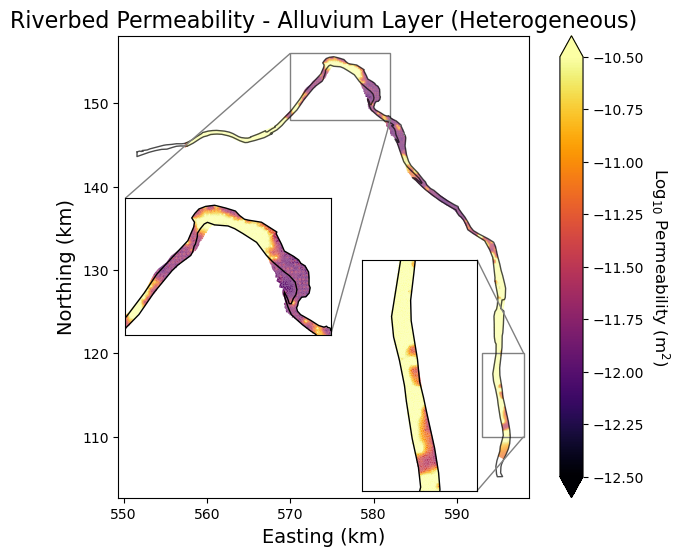

In [19]:
# In[10]:


# --- generate and save spatial map ---

fig_spatial = plot_perm_spatial(xy_coord, perm_log10)
fig_spatial.savefig('../figures/perm_alluvium_2d.jpg', dpi=300, bbox_inches='tight')
plt.close(fig_spatial)

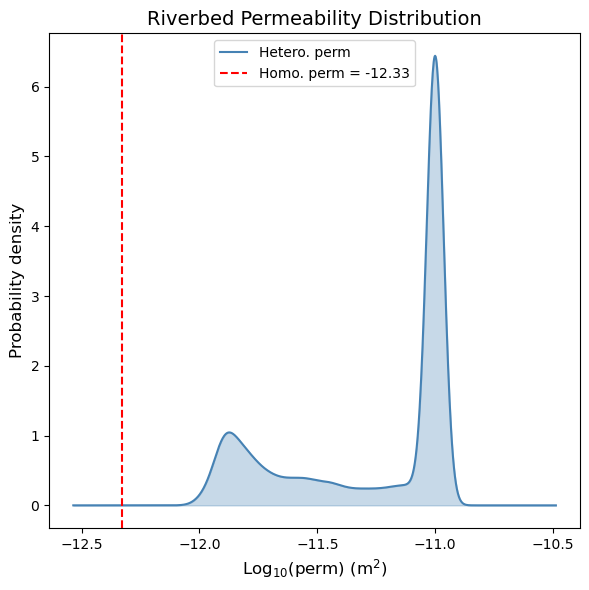

In [15]:
# In[11]:


# --- KDE comparison: heterogeneous vs. homogeneous permeability ---

alluvium_perm_vals = centroid_df.loc[
    (centroid_df['river_idx'] == True) & (centroid_df['mat_ids'] == 10),
    'perm_value'
]
alluvium_log10 = np.log10(alluvium_perm_vals[alluvium_perm_vals > 0])

fig_kde, ax_kde = plt.subplots(figsize=(6, 6))

pd.Series(alluvium_log10).plot.density(ax=ax_kde, color='steelblue', label='Hetero. perm')
x_line, y_line = ax_kde.lines[0].get_xdata(), ax_kde.lines[0].get_ydata()
ax_kde.fill_between(x_line, y_line, alpha=0.3, color='steelblue')

ax_kde.axvline(homo_perm_log10, color='red', linestyle='--', linewidth=1.5,
               label=f'Homo. perm = {homo_perm_log10}')

ax_kde.set_xlabel(r"Log$_{10}$(perm) (m$^2$)", fontsize=12)
ax_kde.set_ylabel("Probability density", fontsize=12)
ax_kde.set_title("Riverbed Permeability Distribution", fontsize=14)
ax_kde.legend()
plt.tight_layout()
plt.show()

In [ ]:
# In[12]:


# --- save KDE figure ---

fig_kde.savefig('../figures/perm_alluvium_kde_comparison.jpg', dpi=300, bbox_inches='tight')
plt.close(fig_kde)